# Assignment 8: Ensemble Methods (Feature Importance & AdaBoost.M1)
**Total Marks: 20**

**Objective:** Implement Random Forest and AdaBoost.M1 for classification from scratch, handle corrupted data, and extract model interpretability metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## Part 1: Data Handling and Pre-processing (3 Marks Total)

### Task 1.1: Load the Dataset (0.5 Marks)
Load the Breast Cancer Wisconsin (Diagnostic) dataset from `sklearn.datasets` and extract the features (`X`), targets (`y`), and feature names.

In [2]:
from sklearn.datasets import load_breast_cancer

# Load dataset and assign X, y, and feature_names
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
target_names = data.target_names

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("\nFeature names:", feature_names)
print("\nTarget names:", target_names)

Shape of X: (569, 30)
Shape of y: (569,)

Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Target names: ['malignant' 'benign']


### Task 1.2: Inject Missing Values (1 Mark)
Artificially corrupt the dataset by randomly masking exactly 5% of the elements in the feature matrix `X` as `np.nan`.

In [3]:
# Calculate 5% of total elements in X, randomly select indices, and set them to np.nan
X_corrupt = X.copy()
n_missing = int(0.05 * X_corrupt.size)
missing_idx = np.random.choice(X_corrupt.size, n_missing, replace=False)
X_corrupt.flat[missing_idx] = np.nan

print("Count of missing values")
missing_count = np.isnan(X_corrupt).sum(axis=0)
for name, count in zip(feature_names, missing_count):
    print(f"{name}: {count}")
    
print(f"\nTotal missing values = {missing_count.sum()} ({(missing_count.sum() / X_corrupt.size * 100):.2f} %)")

Count of missing values
mean radius: 34
mean texture: 19
mean perimeter: 23
mean area: 27
mean smoothness: 25
mean compactness: 24
mean concavity: 24
mean concave points: 29
mean symmetry: 41
mean fractal dimension: 37
radius error: 24
texture error: 28
perimeter error: 21
area error: 27
smoothness error: 31
compactness error: 20
concavity error: 24
concave points error: 26
symmetry error: 37
fractal dimension error: 24
worst radius: 31
worst texture: 30
worst perimeter: 31
worst area: 33
worst smoothness: 28
worst compactness: 23
worst concavity: 35
worst concave points: 33
worst symmetry: 27
worst fractal dimension: 37

Total missing values = 853 (5.00 %)


### Task 1.3: Impute Missing Data (1 Mark)
Initialize a `KNNImputer` (e.g., `n_neighbors=5`) and impute the missing values in your corrupted feature matrix.

In [4]:
# Initialize KNNImputer and fit_transform X
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(X_corrupt)

print("Shape after imputation:", X_imputed.shape)
print("Remaining missing values:", np.isnan(X_imputed).sum())

Shape after imputation: (569, 30)
Remaining missing values: 0


### Task 1.4: Stratified Train-Validation-Test Split (0.5 Marks)
Perform a stratified split of the dataset into training (70%), validation (15%), and test (15%) sets. Ensure `stratify=y` is used.

In [5]:
# Perform split. (Hint: Use train_test_split twice)
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(X_imputed, y, test_size=0.3, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp)

print(f"Shape of training dataset: X = {X_train.shape}, y = {y_train.shape}")
print(f"Shape of validation dataset: X = {X_val.shape}, y = {y_val.shape}")
print(f"Shape of testing dataset: X = {X_test.shape}, y = {y_test.shape}")

Shape of training dataset: X = (398, 30), y = (398,)
Shape of validation dataset: X = (85, 30), y = (85,)
Shape of testing dataset: X = (86, 30), y = (86,)


## Part 2: Random Forest Classification from Scratch (7 Marks Total)

### Task 2.1: Implement Decision Tree with Gini Tracking (3 Marks)
Build a base `CustomDecisionTree` class. Your implementation must track the **Mean Decrease in Impurity (Gini)** for each feature used during a split to allow for Feature Importance calculation.

In [6]:
class CustomDecisionTree:
    def __init__(self, max_depth=5, max_features='sqrt', random_state=None):
        self.max_depth = max_depth
        self.max_features = max_features
        self.random_state = random_state
        self.feature_importances_ = None
        self.root = None

    def _gini(self, y):
        """
        Calculate Gini impurity
        """
        if len(y) == 0:
            return 0.0
        
        probabilities = np.bincount(y) / len(y)
        return 1 - np.sum(probabilities ** 2)

    def _best_split(self, X, y, feature_indices):
        """
        Find the split with the maximum weighted Gini decrease
        """
        best_gain = 0.0
        best_split = None
        n_samples = len(y)

        parent_gini = self._gini(y)

        for feature in feature_indices:
            values = np.unique(X[:, feature])
            thresholds = (values[:-1] + values[1:]) / 2

            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                right_mask = ~left_mask
                if not left_mask.any() or not right_mask.any():
                    continue

                y_left = y[left_mask]
                y_right = y[right_mask]

                # Calculate sample-weighted Gini decrease
                weighted_gini = (len(y_left) / n_samples * self._gini(y_left) + len(y_right) / n_samples * self._gini(y_right))
                gain = parent_gini - weighted_gini
                if gain > best_gain:
                    best_gain = gain
                    best_split = (feature, threshold, gain)

        return best_split

    def _grow_tree(self, X, y, depth):
        """
        Create a leaf using the majority class
        """
        predicted_class = np.bincount(y).argmax()

        # Stop when the node is pure or maximum depth is reached
        if len(np.unique(y)) == 1 or depth >= self.max_depth:
            return {'predicted_class': predicted_class}

        n_features = X.shape[1]

        # Select features to consider at this node
        if self.max_features == 'sqrt':
            n_selected = max(1, int(np.sqrt(n_features)))
        elif self.max_features == 'log2':
            n_selected = max(1, int(np.log2(n_features)))
        elif self.max_features is None:
            n_selected = n_features
        elif isinstance(self.max_features, int) and not isinstance(self.max_features, bool):
            if not 1 <= self.max_features <= n_features:
                raise ValueError("max_features must be between 1 and n_features")
            n_selected = self.max_features
        else:
            raise ValueError("Invalid max_features value")

        feature_indices = self.rng.choice(n_features, n_selected, replace=False)

        # Find the best split
        split = self._best_split(X, y, feature_indices)
        if split is None:
            return {'predicted_class': predicted_class}

        feature, threshold, gain = split
        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        # Track total weighted impurity decrease for this feature
        self.feature_importances_[feature] += (len(y) / self.n_samples * gain)

        # Recursively grow the left and right subtrees
        left = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
        right = self._grow_tree(X[right_mask], y[right_mask], depth + 1)

        return {
            'feature': feature,
            'threshold': threshold,
            'left': left,
            'right': right
        }

    def _traverse_tree(self, x, node):
        # Return prediction when a leaf is reached
        if 'predicted_class' in node:
            return node['predicted_class']

        # Follow the appropriate branch
        if x[node['feature']] <= node['threshold']:
            return self._traverse_tree(x, node['left'])

        return self._traverse_tree(x, node['right'])

    def fit(self, X, y):
        """
        Train the decision tree
        """
        # Set a dedicated random number generator (RNG)
        self.rng = np.random.default_rng(self.random_state)
        
        # Convert inputs to NumPy arrays
        X = np.asarray(X)
        y = np.asarray(y)

        # Encode class labels as integers for bincount
        self.classes_, y_encoded = np.unique(y, return_inverse=True)

        self.n_samples = len(y_encoded)
        self.feature_importances_ = np.zeros(X.shape[1])

        # Grow the tree
        self.root = self._grow_tree(X, y_encoded, depth=0)

        # Normalize feature importances
        total_importance = self.feature_importances_.sum()
        if total_importance > 0:
            self.feature_importances_ /= total_importance

        return self

    def predict(self, X):
        """
        Predict labels and convert encoded predictions back to original classes
        """
        X = np.asarray(X)
        predictions = np.array([self._traverse_tree(x, self.root) for x in X])
        return self.classes_[predictions]
    

### Task 2.2: Implement Custom Random Forest with OOB Error (2 Marks)
Build the `CustomRandomForest` class. Implement bootstrap sampling, fit the base trees, calculate the Out-Of-Bag (OOB) error, and average the feature importances from all trees.

**Random Forest — Key Expressions**

**1. Bootstrap Sampling**

For a training dataset with \(N\) samples, draw \(N\) samples with replacement to construct each bootstrap dataset:

$$
D_m \sim \operatorname{Bootstrap}(D), \quad m=1,\ldots,M
$$

where \(M\) is the number of decision trees.

**2. Gini Impurity**

For a node \(S\) containing \(K\) classes:

$$
Gini(S)=1-\sum_{k=1}^{K}p_k^2
$$

where \($p_k$\) is the proportion of samples belonging to class \(k\).

**3. Weighted Gini Impurity After a Split**

For a split into left and right child nodes:

$$
Gini_{\mathrm{split}}=
\frac{N_L}{N}Gini(S_L)
+\frac{N_R}{N}Gini(S_R)
$$

where \(N\), \(N_L\), and \(N_R\) are the numbers of samples in the parent, left, and right nodes, respectively.

**4. Gini Impurity Decrease**

$$
\Delta Gini =
Gini(S)-Gini_{\mathrm{split}}
$$

The split with the largest impurity decrease is preferred.

**5. Feature Importance Within a Tree**

The importance of feature \(j\) is the sum of sample-weighted impurity decreases over all nodes split using that feature:

$$
I_j^{(m)}=
\sum_{v:\,\operatorname{feature}(v)=j}
\frac{N_v}{N_{\mathrm{train}}}\Delta Gini_v
$$

Normalize the feature importances within each tree:

$$
FI_j^{(m)}=
\frac{I_j^{(m)}}{\sum_{k=1}^{d}I_k^{(m)}}
$$

where \(d\) is the number of features, provided the denominator is nonzero.

**6. Random Forest Feature Importance**

Average the normalized feature importances across all \(M\) trees:

$$
FI_j=\frac{1}{M}\sum_{m=1}^{M}FI_j^{(m)}
$$

**7. Majority-Vote Prediction**

Each tree predicts a class, and the forest returns the most frequently predicted class:

$$
\hat{y}(x)=
\operatorname{mode}\left(
h_1(x),h_2(x),\ldots,h_M(x)
\right)
$$

**8. Out-of-Bag (OOB) Prediction**

For training sample \(i\), let \($\mathcal{T}_i$\) be the set of trees whose bootstrap samples excluded that sample:

$$
\hat{y}_i^{\mathrm{OOB}}=
\operatorname{mode}\{h_m(x_i):m\in\mathcal{T}_i\}
$$

Only samples receiving at least one OOB prediction are used to calculate the OOB error.

**9. OOB Error**

$$
\operatorname{OOBError}=
\frac{1}{|\mathcal{S}_{\mathrm{OOB}}|}
\sum_{i\in\mathcal{S}_{\mathrm{OOB}}}
\mathbb{1}\left(\hat{y}_i^{\mathrm{OOB}}\neq y_i\right)
$$

where \($\mathcal{S}_{\mathrm{OOB}}$\) is the set of training samples with at least one OOB prediction.

**10. Test Accuracy**

$$
\operatorname{Accuracy}=
\frac{1}{N_{\mathrm{test}}}
\sum_{i=1}^{N_{\mathrm{test}}}
\mathbb{1}\left(\hat{y}_i=y_i\right)
$$

**Key Idea:** Random Forest combines bootstrap sampling, random feature selection, and aggregation across multiple decision trees to reduce variance and improve generalization.

In [7]:
class CustomRandomForest:
    def __init__(self, n_trees=100, max_depth=5, max_features='sqrt', random_state=None):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.random_state = random_state
        self.trees = []
        self.feature_importances_ = None
        self.oob_error_ = None

    def fit(self, X, y):
        """
        Train the Random Forest
        """
        X = np.asarray(X)
        y = np.asarray(y)

        n_samples, n_features = X.shape
        self.trees = []
        
        # Set a dedicated random number generator (RNG)
        rng = np.random.default_rng(self.random_state)

        # Store OOB votes for each sample and class
        self.classes_ = np.unique(y)
        oob_votes = np.zeros((n_samples, len(self.classes_)), dtype=int)

        # Fit each tree using bootstrap sampling
        for _ in range(self.n_trees):
            bootstrap_idx = rng.choice(n_samples, n_samples, replace=True)
            oob_idx = np.setdiff1d(np.arange(n_samples), np.unique(bootstrap_idx))

            # Train a custom decision tree with separate reproducible random seed
            tree_seed = int(rng.integers(0, 2**32 - 1))
            tree = CustomDecisionTree(max_depth=self.max_depth, max_features=self.max_features, random_state=tree_seed)
            tree.fit(X[bootstrap_idx], y[bootstrap_idx])
            self.trees.append(tree)

            # Collect predictions for out-of-bag samples
            if len(oob_idx) > 0:
                oob_pred = tree.predict(X[oob_idx])
                for i, pred in zip(oob_idx, oob_pred):
                    class_idx = np.where(self.classes_ == pred)[0][0]
                    oob_votes[i, class_idx] += 1

        # Calculate OOB error using samples that received at least one OOB vote
        oob_counts = oob_votes.sum(axis=1)
        valid_samples = oob_counts > 0

        if np.any(valid_samples):
            oob_pred = self.classes_[np.argmax(oob_votes[valid_samples], axis=1)]
            self.oob_error_ = np.mean(oob_pred != y[valid_samples])
        else:
            self.oob_error_ = np.nan

        # Average feature importances across all trees
        self.feature_importances_ = np.mean([tree.feature_importances_ for tree in self.trees], axis=0)
        
        return self

    def predict(self, X):
        """
        Aggregate predictions from all the trees
        """
        X = np.asarray(X)

        # Collect predictions from all trees
        predictions = np.array([tree.predict(X) for tree in self.trees])

        # Majority vote for each sample
        final_predictions = []
        for sample_predictions in predictions.T:
            values, counts = np.unique(sample_predictions, return_counts=True)
            final_predictions.append(values[np.argmax(counts)])

        return np.asarray(final_predictions)
    

### Task 2.3: Train, Evaluate, and Plot Importances (2 Marks)
Train your `CustomRandomForest` on the training set. Predict on the test set, print the accuracy and OOB error. Finally, create a horizontal bar chart displaying the top 10 most important features.

Test accuracy = 0.9651
OOB error = 0.0452


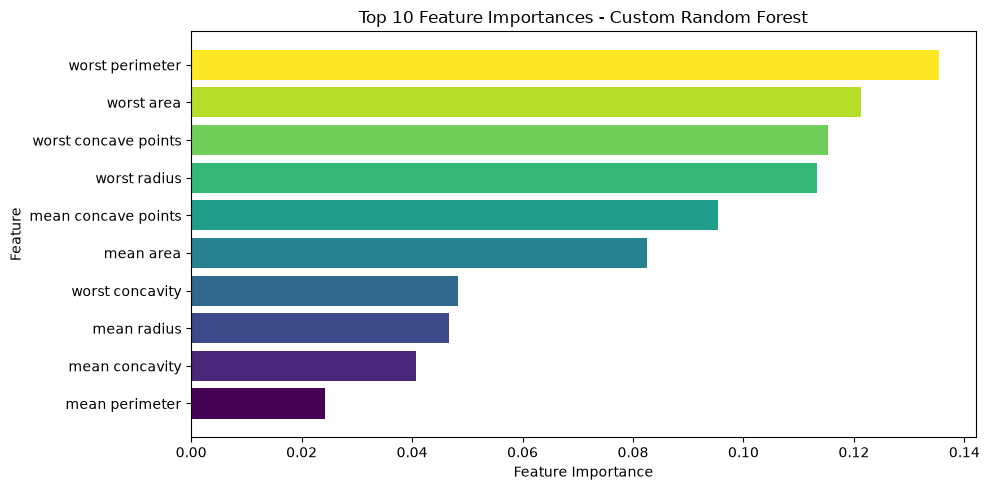

In [8]:
from sklearn.metrics import accuracy_score

# Initialize and fit CustomRandomForest
rf = CustomRandomForest(n_trees=100, max_depth=5, max_features="sqrt", random_state=RANDOM_SEED)
rf.fit(X_train, y_train)

# Predict on X_test and print test accuracy and OOB error
y_pred = rf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy = {test_accuracy:.4f}")
print(f"OOB error = {rf.oob_error_:.4f}")

# Plot Top 10 Feature Importances using feature_names
importances = rf.feature_importances_
top_idx = np.argsort(importances)[-10:]

plt.figure(figsize=(10, 5))
plt.barh(feature_names[top_idx], importances[top_idx], color=plt.cm.viridis(np.linspace(0, 1, len(top_idx))))
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Custom Random Forest")
plt.tight_layout()
plt.savefig("plots/random_forest_feature_importances.png")

## Part 3: AdaBoost.M1 from Scratch (7 Marks Total)

### Task 3.1: Implement AdaBoost.M1 Classifier (4 Marks)
Implement AdaBoost.M1 for binary classification. Your `fit` method must calculate validation accuracy at each boosting stage $m$ and store it in a list. *(Note: Ensure your `y` labels are mapped to `{-1, 1}` for the standard AdaBoost exponential loss math to work).*

**AdaBoost.M1**

**1. Initialize Sample Weights**

For \(N\) training samples, assign equal initial weights:

$$
w_i^{(1)}=\frac{1}{N},\quad i=1,\ldots,N
$$

**2. Weighted Classification Error**

For weak learner \($h_m(x)$\) at boosting stage \(m\):

$$
\epsilon_m=\sum_{i=1}^{N}w_i^{(m)}
\mathbb{1}\left(h_m(x_i)\neq y_i\right)
$$

**3. Calculate Weak Learner Weight**

$$
\alpha_m=\frac{1}{2}\ln\left(\frac{1-\epsilon_m}{\epsilon_m}\right)
$$

A lower weighted error gives the weak learner a higher weight in the final ensemble.

**4. Update Sample Weights**

For labels \($y_i\in\{-1,+1\}$\) and predictions \($h_m(x_i)\in\{-1,+1\}$\):

$$
w_i^{(m+1)}=w_i^{(m)}
\exp\left(-\alpha_m y_i h_m(x_i)\right)
$$

- Correct prediction: the sample weight decreases.
- Incorrect prediction: the sample weight increases.

**5. Normalize Sample Weights**

$$
w_i^{(m+1)}\leftarrow
\frac{w_i^{(m+1)}}{\sum_{j=1}^{N}w_j^{(m+1)}}
$$

This ensures that the sample weights sum to \(1\).

**6. Final Ensemble Prediction**

After \(M\) boosting stages:

$$
H(x)=\operatorname{sign}\left(
\sum_{m=1}^{M}\alpha_m h_m(x)
\right)
$$

**7. Validation Accuracy at Stage \(m\)**

$$
\operatorname{ValAccuracy}_m=
\frac{1}{N_{\mathrm{val}}}
\sum_{i=1}^{N_{\mathrm{val}}}
\mathbb{1}\left(H_m(x_i^{\mathrm{val}})=y_i^{\mathrm{val}}\right)
$$

where

$$
H_m(x)=\operatorname{sign}\left(
\sum_{t=1}^{m}\alpha_t h_t(x)
\right)
$$

Store the validation accuracy after each boosting stage in `self.val_accuracies`.

**Note:** 
- AdaBoost.M1 requires binary labels encoded as \(\{-1,+1\}\) for these exponential-loss expressions. 
- A weak learner with weighted error \($\epsilon_m\geq 0.5$\) should not be added to the ensemble.

In [9]:
from sklearn.tree import DecisionTreeClassifier

class CustomAdaBoostM1:
    def __init__(self, M=50):
        self.M = M
        self.models = []
        self.alphas = []
        self.val_accuracies = []

    def fit(self, X, y, X_val, y_val):
        """
        Train the AdaBoost.M1 model
        """
        # Map binary labels to {-1, 1}
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError("AdaBoost.M1 requires binary classification!")
        
        y = np.where(y == self.classes_[0], -1, 1)
        y_val = np.where(y_val == self.classes_[0], -1, 1)
        
        # Initialize sample weights
        n_samples = X.shape[0]
        w = np.ones(n_samples) / n_samples
        
        # Reset model state
        self.models = []
        self.alphas = []
        self.val_accuracies = []

        for m in range(self.M):
            # Fit a DecisionTreeClassifier (max_depth=1) using sample_weight=w
            model = DecisionTreeClassifier(max_depth=1, random_state=m)
            model.fit(X, y, sample_weight=w)
            
            # Calculate weighted error (err_m)
            y_pred = model.predict(X)
            err_m = np.sum(w * (y_pred != y))
            if err_m >= 0.5:
                break           # Stop if the weak learner is no better than random guessing
            
            # Calculate stage weight (alpha_m)
            err_m = np.clip(err_m, 1e-10, 1 - 1e-10)
            alpha_m = 0.5 * np.log((1 - err_m) / err_m)
            
            # Update and normalize sample weights (w)
            w *= np.exp(-alpha_m * y * y_pred)
            w /= np.sum(w)
            
            # Save the model and alpha
            self.models.append(model)
            self.alphas.append(alpha_m)

            # Predict on X_val using the ensemble built up to stage m
            y_val_pred = self.predict(X_val)
            
            # Append the current validation accuracy to self.val_accuracies
            self.val_accuracies.append(accuracy_score(y_val, y_val_pred))
            
        return self

    def predict(self, X):
        """
        Aggregate predictions weighted by self.alphas. Return the sign() of the sum.
        """
        if not self.models:
            raise ValueError("No weak learners were trained successfully.")
        
        predictions = np.array([model.predict(X) for model in self.models])
        weighted_sum = np.dot(np.asarray(self.alphas), predictions)
        y_pred = np.sign(weighted_sum)
        y_pred[y_pred == 0] = 1         # Tie -> positive class
        
        return y_pred
    

### Task 3.2: Train, Plot Learning Curve, and Evaluate (3 Marks)
Map your labels to `{-1, 1}`, fit the `CustomAdaBoostM1` model, and plot a line chart of **Validation Accuracy vs. Number of Weak Learners (M)**. Lastly, report the final Test Accuracy.

No. of weak learners = 50
Test accuracy = 0.9767


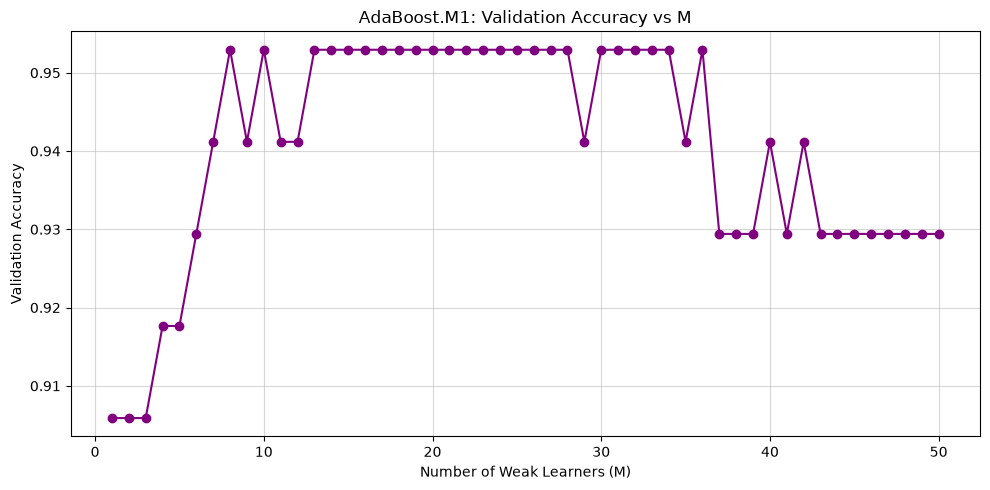

In [10]:
# Map y_train, y_val, y_test to {-1, 1}
classes = np.unique(y_train)
y_train_encoded = np.where(y_train == classes[0], -1, 1)
y_val_encoded = np.where(y_val == classes[0], -1, 1)
y_test_encoded = np.where(y_test == classes[0], -1, 1)

# Initialize and fit CustomAdaBoostM1 with M=50
ada = CustomAdaBoostM1(M=50)
ada.fit(X_train, y_train, X_val, y_val)     # Custom implementation already encodes y_train and y_val internally

# Plot Validation Accuracy vs M
n_learners = len(ada.val_accuracies)

plt.figure(figsize=(10, 5))
plt.plot(range(1, n_learners + 1), ada.val_accuracies, marker='o', color = "purple")
plt.xlabel("Number of Weak Learners (M)")
plt.ylabel("Validation Accuracy")
plt.title("AdaBoost.M1: Validation Accuracy vs M")
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.savefig("plots/adaboost_val_accuracy.png")

# Predict on X_test and print Final Test Accuracy
y_pred = ada.predict(X_test)
test_accuracy = accuracy_score(y_test_encoded, y_pred)
print("No. of weak learners =", n_learners)
print(f"Test accuracy = {test_accuracy:.4f}")

## Part 4: Scikit-Learn Comparison & Hyperparameter Tuning (3 Marks Total)

### Task 4.1: Feature Importance Validation (1.5 Marks)
Train `sklearn.ensemble.RandomForestClassifier` on the training data using the same hyperparameters. Extract its feature importances and print the Top 3 features. Print your custom RF's Top 3 features alongside it for comparison.

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Train sklearn RandomForestClassifier
sklearn_rf = RandomForestClassifier(n_estimators=100, max_depth=5, max_features="sqrt", random_state=RANDOM_SEED)
sklearn_rf.fit(X_train, y_train)

# Print Top 3 features from sklearn
sklearn_importances = sklearn_rf.feature_importances_
sklearn_top_3 = np.argsort(sklearn_importances)[-3:][::-1]

# Print Top 3 features from CustomRandomForest
custom_importances = rf.feature_importances_
custom_top_3 = np.argsort(custom_importances)[-3:][::-1]

# Display comparison
comparison_df = pd.DataFrame({
    "Rank": [1, 2, 3],
    "Scikit-Learn RF Feature": feature_names[sklearn_top_3],
    "Scikit-Learn RF Importance": sklearn_importances[sklearn_top_3],
    "Custom RF Feature": feature_names[custom_top_3],
    "Custom RF Importance": custom_importances[custom_top_3]
})
display(comparison_df.round(4))

,Rank,Scikit-Learn RF Feature,Scikit-Learn RF Importance,Custom RF Feature,Custom RF Importance
0,1,worst area,0.1675,worst perimeter,0.1353
1,2,worst concave points,0.1024,worst area,0.1213
2,3,mean concave points,0.0917,worst concave points,0.1153


### Task 4.2: AdaBoost Grid Search (1.5 Marks)
Define a parameter grid for `sklearn.ensemble.AdaBoostClassifier` (e.g., testing different `learning_rate` and `n_estimators` values). Run `GridSearchCV` on the training data and report the best parameters and final test accuracy.

In [12]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV

# TODO: Define param_grid and initialize GridSearchCV with AdaBoostClassifier
param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5]
}
sklearn_ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=RANDOM_SEED)

# Fit grid search (with 5-fold cross-validation)
grid_search = GridSearchCV(estimator=sklearn_ada, param_grid=param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid_search.fit(X_train, y_train)

# TODO: Print best_params_ and test accuracy
best_ada = grid_search.best_estimator_
y_pred = best_ada.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

print("Best Parameters:", grid_search.best_params_)
print(f"Final Test Accuracy: {test_accuracy:.4f}")

Best Parameters: {'learning_rate': 0.05, 'n_estimators': 150}
Final Test Accuracy: 0.9767


---
End of the assignment